In [1]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Configurações iniciais
ARQUIVO_DADOS = "/kaggle/input/datasets/juliaduboisas/train-limpo/train_limpo.csv"
COLUNA_TEXTO = "resp_text"     # Substitua pelo nome correto
COLUNA_ALVO = "clarity"    # Substitua pelo nome correto

# Carregar dados
df = pd.read_csv(ARQUIVO_DADOS)

# Mapear as classes para números inteiros
mapeamento_classes = {'c1': 0, 'c234': 1, 'c5': 2}
df['label'] = df[COLUNA_ALVO].map(mapeamento_classes)

# Remover valores nulos e resetar o index (crucial para o Stacking)
df = df.dropna(subset=[COLUNA_TEXTO, 'label'])
df['label'] = df['label'].astype(int)
df = df.reset_index(drop=True)

print(f"Total de amostras: {len(df)}")
print(df['label'].value_counts())

Total de amostras: 20092
label
2    6892
1    6853
0    6347
Name: count, dtype: int64


In [3]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenizar_dados(exemplos):
    return tokenizer(exemplos['texto'], padding="max_length", truncation=True, max_length=256)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [4]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Matrizes para guardar as probabilidades Out-Of-Fold (OOF)
# Formato: [Número de amostras, Número de classes (3)]
oof_lr = np.zeros((len(df), 3))
oof_bert = np.zeros((len(df), 3))

for fold, (train_idx, val_idx) in enumerate(skf.split(df[COLUNA_TEXTO], df['label'])):
    print(f"\n{'='*30}\nIniciando Fold {fold + 1}/3\n{'='*30}")
    
    df_train = df.iloc[train_idx].copy()
    df_val = df.iloc[val_idx].copy()
    
    # ==========================================
    # 1. MODELO BASE 1: Regressão Logística + TF-IDF
    # ==========================================
    print("Treinando Modelo 1: Regressão Logística...")
    tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), max_features=10000)
    
    X_train_tfidf = tfidf.fit_transform(df_train[COLUNA_TEXTO])
    X_val_tfidf = tfidf.transform(df_val[COLUNA_TEXTO])
    
    lr_model = LogisticRegression(C=2, max_iter=1000, random_state=42)
    lr_model.fit(X_train_tfidf, df_train['label'])
    
    # Salvar as probabilidades na matriz OOF
    oof_lr[val_idx] = lr_model.predict_proba(X_val_tfidf)
    
    # ==========================================
    # 2. MODELO BASE 2: Fine-tuning Bertimbau
    # ==========================================
    print("Treinando Modelo 2: Bertimbau...")
    ds_train = Dataset.from_pandas(df_train[[COLUNA_TEXTO, 'label']].rename(columns={COLUNA_TEXTO: 'texto'}))
    ds_val = Dataset.from_pandas(df_val[[COLUNA_TEXTO, 'label']].rename(columns={COLUNA_TEXTO: 'texto'}))
    
    # É normal o warning de colunas extras aqui se o pandas mantiver a coluna "__index_level_0__"
    ds_train = ds_train.map(tokenizar_dados, batched=True)
    ds_val = ds_val.map(tokenizar_dados, batched=True)
    
    ds_train.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    ds_val.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
    
    bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
    
    training_args = TrainingArguments(
        output_dir=f'./results_fold_{fold}',
        num_train_epochs=3,              
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        weight_decay=0.01,
        logging_steps=50,
        eval_strategy="epoch",  
        save_strategy="epoch",
        load_best_model_at_end=True,
        report_to="none"
    )
    
    trainer = Trainer(
        model=bert_model,
        args=training_args,
        train_dataset=ds_train,
        eval_dataset=ds_val,
    )
    
    trainer.train()
    
    # Extrair logits, aplicar softmax e salvar na matriz OOF
    logits_bert = trainer.predict(ds_val).predictions
    probs_bert = torch.nn.functional.softmax(torch.tensor(logits_bert), dim=-1).numpy()
    oof_bert[val_idx] = probs_bert
    
    # Limpeza de memória
    del bert_model
    del trainer
    torch.cuda.empty_cache()


Iniciando Fold 1/3
Treinando Modelo 1: Regressão Logística...
Treinando Modelo 2: Bertimbau...


Map:   0%|          | 0/13394 [00:00<?, ? examples/s]

Map:   0%|          | 0/6698 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (21 outputs left out)

Epoch,Training Loss,Validation Loss
1,2.102204,2.095094
2,1.993665,2.085594
3,1.701264,2.230851


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TREINANDO O META-MODELO (STACKING)
Acurácia Global do Stacking: 0.4593

Relatório de Classificação Global do Stacking:
              precision    recall  f1-score   support

          c1       0.48      0.49      0.49      6347
        c234       0.39      0.33      0.36      6853
          c5       0.49      0.55      0.52      6892

    accuracy                           0.46     20092
   macro avg       0.46      0.46      0.46     20092
weighted avg       0.45      0.46      0.46     20092



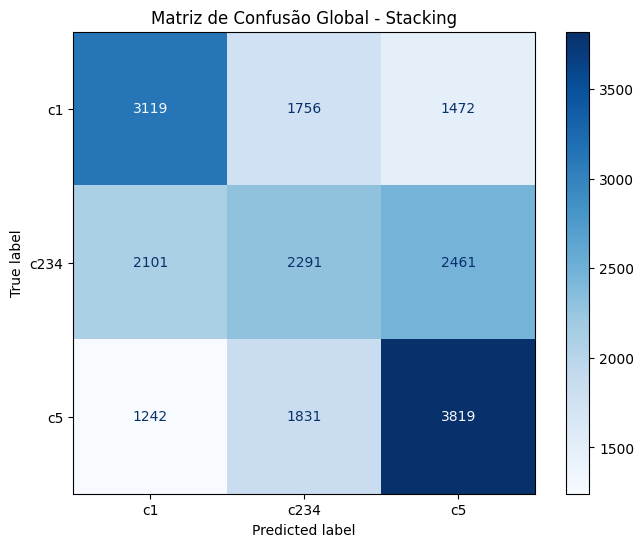

In [5]:
print("\n" + "="*40)
print("TREINANDO O META-MODELO (STACKING)")
print("="*40)

# Unir as probabilidades geradas pelos modelos base (Features do Meta-Modelo)
# X_meta terá 6 colunas
X_meta = np.hstack((oof_lr, oof_bert))
y_true = df['label'].values

# O Meta-Modelo é uma Regressão Logística nova
meta_model = LogisticRegression(random_state=42)

# Vamos validá-lo com Cross Validation nas previsões OOF para obter a performance final
preds_stacking = cross_val_predict(meta_model, X_meta, y_true, cv=3)

# Avaliação do Stacking
acc_stacking = accuracy_score(y_true, preds_stacking)
print(f"Acurácia Global do Stacking: {acc_stacking:.4f}")

print("\nRelatório de Classificação Global do Stacking:")
target_names = ['c1', 'c234', 'c5']
print(classification_report(y_true, preds_stacking, target_names=target_names))

# Gerar e exibir a Matriz de Confusão
cm = confusion_matrix(y_true, preds_stacking)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title('Matriz de Confusão Global - Stacking')
plt.show()